# Скоринг МСБ: исследование и обучение моделей

Ноутбук воспроизводит весь путь от данных до моделей, которые лежат в БД и применяются конвейером:

1. **Данные** — синтетика `ml/data/synthetic_v1`: кредитные истории из соревнования (scoring_maps) + сгенерированный бизнес-профиль МСБ.
2. **Срезы распределений** — где риск разный и почему это важно для модели.
3. **Матрица переходов** статусов платежей — определение дефолта и веса просрочек.
4. **Биннинг, WoE и IV** — отбор признаков и их веса.
5. **Модели**: общая скоркарта, три сегментные, challenger на градиентном бустинге.
6. **Валидация**: Gini/KS на train/valid/OOT, калибровка, PSI, стабильность по кварталам.
7. **Выбор чемпиона для каждого сегмента** и правила, когда какую модель применять.
8. **Экспорт** в `ml/artifacts/models.json` → загрузка в БД (`scoring_segments`, `model_versions`, `scorecard_bins`, `rating_scale`).

Все данные синтетические. Признаки считаются тем же кодом, что в приложении: `src/app/credit/features.py`.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split

ML_DIR = Path.cwd() if (Path.cwd() / "scorecard_lib.py").exists() else Path.cwd() / "ml"
sys.path.insert(0, str(ML_DIR))
sys.path.insert(0, str(ML_DIR.parent / "src"))

import scorecard_lib as sl

from app.credit import features as F
from app.credit import scorecard as SC

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 40)
sns.set_theme(style="whitegrid", font_scale=0.9)
plt.rcParams["figure.dpi"] = 90

DATA = ML_DIR / "data" / "synthetic_v1"
ARTIFACTS = ML_DIR / "artifacts"
ARTIFACTS.mkdir(exist_ok=True)
RANDOM_STATE = 42

manifest = json.loads((DATA / "manifest.json").read_text(encoding="utf-8"))
print(json.dumps(manifest, ensure_ascii=False, indent=1))

{
 "dataset_code": "synthetic_v1",
 "seed": 2026,
 "companies": 40000,
 "bad_share": 0.05,
 "as_of_range": [
  "2023-01-01",
  "2025-09-30"
 ],
 "beta": 1.15,
 "tables": {
  "companies": 40000,
  "company_okved": 40000,
  "okved_codes": 14,
  "obligations": 281998,
  "fssp": 9223,
  "turnovers": 448619
 },
 "payment_string": "индекс 0 — последний полный месяц перед заявкой; 0 без просрочки, 1 до 30 дн., 2 30+ дн., - нет данных"
}


## 1. Данные

**Откуда синтетика.** В соревновании scoring_maps одна заявка (`id`) — это набор кредитов из БКИ (`rn`) с помесячными статусами платежей `enc_paym_0..24` и таргетом `flag` (дефолт по новому кредиту). Мы трактуем заявку как заявку компании МСБ: её кредиты → `credit_obligations`, статусы → строка платёжной дисциплины `payment_string` (позиция 0 — последний месяц перед заявкой: `0` без просрочки, `1` до 30 дней, `2` 30+ дней, `-` нет данных). К ней генерируется компания: ОПФ, ОКВЭД, регион, возраст, категория МСП, обороты за 12 месяцев, налоги, ФССП, ЗСК. Бизнес-признаки зависят от скрытого риска `r = 1.15·flag + N(0,1)` — у дефолтных компаний они хуже в среднем, но распределения сильно перекрываются.

**Что такое таргет.** `target = 1` — дефолт (90+ дней просрочки или банкротство) в течение 12 месяцев после даты заявки `as_of_date`. Заявки упорядочены по времени (в исходнике `id` растёт с датой), даты — с 01.2023 по 09.2025, поэтому у последних заявок окно наблюдения уже закрыто.

**Уровень дефолта** поднят до 5% (в исходнике 3,5%): у МСБ дефолтность выше розничной. Это учтено при калибровке PD.

In [2]:
feats = pd.read_csv(DATA / "features.csv.gz", dtype={"region_code": str, "inn": str})
companies = pd.read_csv(
    DATA / "companies.csv.gz", dtype={"region_code": str, "inn": str, "okved_main": str}
)
obligations = pd.read_csv(
    DATA / "obligations.csv.gz",
    usecols=[
        "company_key",
        "payment_string",
        "opened_at",
        "closed_at",
        "src_since_opened",
    ],
)
feats["as_of_date"] = pd.to_datetime(feats["as_of_date"])
feats = feats.merge(
    companies[["company_key", "zsk_zone"]].rename(columns={"zsk_zone": "zsk_src"}),
    on="company_key",
)
print(
    f"Компаний: {len(feats):,}; кредитов в КИ: {len(obligations):,}; дефолт: {feats.target.mean():.2%}"
)
display(feats.head(3).T)

Компаний: 40,000; кредитов в КИ: 281,998; дефолт: 5.00%


,0,1,2
company_key,17,40,169
inn,52990000100,549900000295,059900000361
as_of_date,2023-01-01 00:00:00,2023-01-01 00:00:00,2023-01-01 00:00:00
target,0,1,0
status,active,active,active
company_age_months,11,7,3
legal_form,ЮЛ,ИП,ИП
msp_category,micro,micro,micro
okved_section,H,F,G
region_code,52,54,05


### Стоп-факторы до модели
Банкроты и компании в красной зоне ЗСК отсекаются жёсткими стоп-факторами ещё до скоринга — модель их никогда не увидит. Если оставить их в обучении, модель «выучит» очевидное и хуже ранжирует остальных. Поэтому они в выборке помечены `excluded`.

In [3]:
hard_stop = (feats.status == "bankrupt") | (feats.zsk_zone == "red")
display(
    feats.assign(hard_stop=hard_stop)
    .groupby("hard_stop")
    .target.agg(["size", "mean"])
    .rename(columns={"size": "компаний", "mean": "дефолт"})
)
pop = feats[~hard_stop].copy()
print(f"В моделировании: {len(pop):,} компаний, дефолт {pop.target.mean():.2%}")

В моделировании: 39,802 компаний, дефолт 4.87%


,компаний,дефолт
hard_stop,,
False,39802,0.04874
True,198,0.303


## 2. Срезы распределений

Срез — это вопрос «одинаково ли устроен риск в разных частях портфеля». От ответа зависят три решения:
* **сегментация** — если риск и его драйверы различаются, одна модель на всех будет ошибаться систематически;
* **разбиение выборки** — если риск дрейфует во времени, проверять модель нужно на более поздних данных (OOT);
* **группировка категорий** — регионы и отрасли с похожим риском объединяем, редкие — в «прочие».

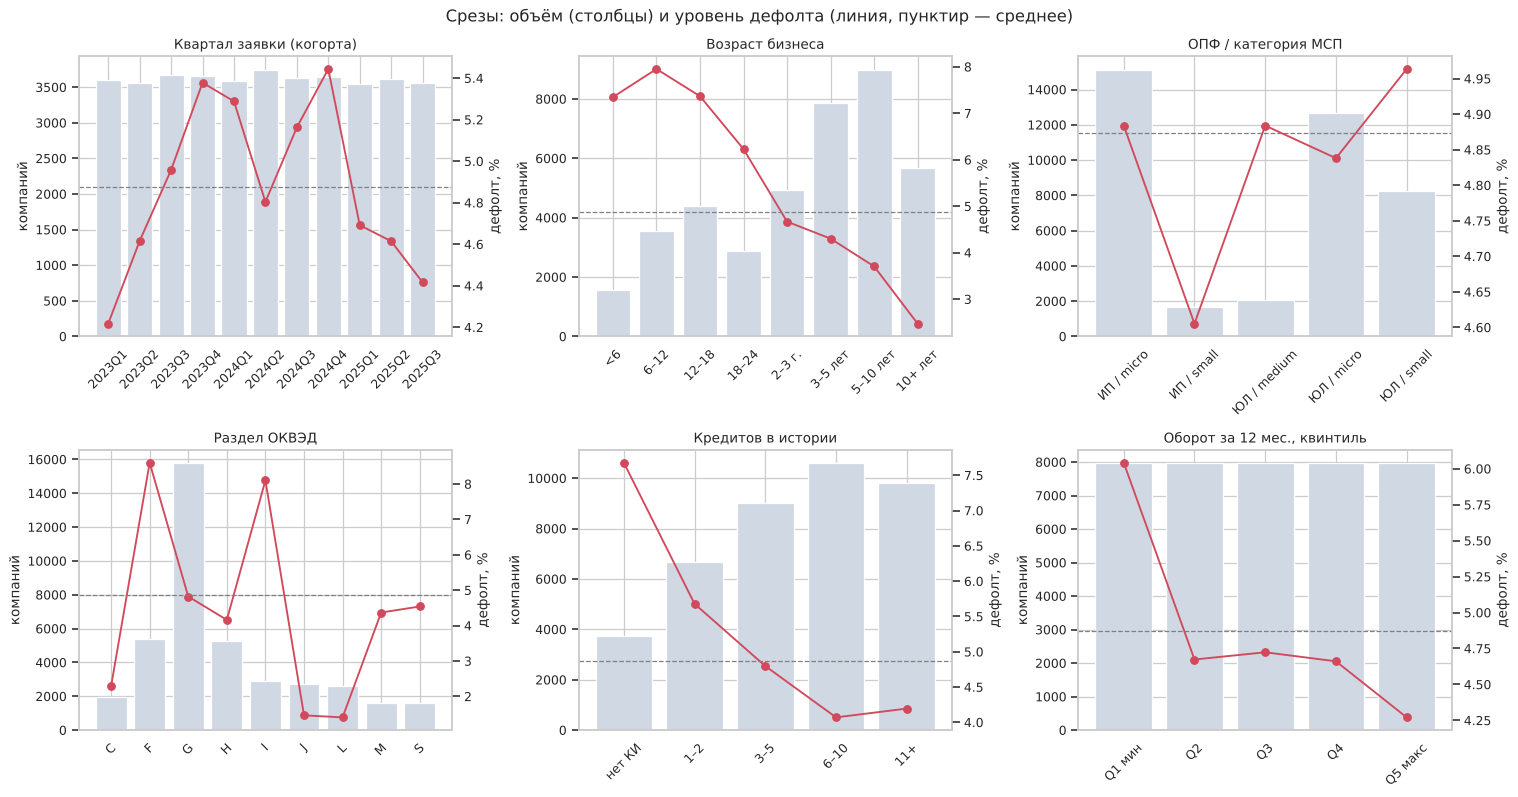

,компаний,дефолт,доля,lift
age_bucket,,,,
<6,1565,0.073,0.039,1.508
6–12,3546,0.08,0.089,1.632
12–18,4385,0.074,0.11,1.511
18–24,2874,0.062,0.072,1.278
2–3 г.,4927,0.047,0.124,0.958
3–5 лет,7856,0.043,0.197,0.883
5–10 лет,8989,0.037,0.226,0.76
10+ лет,5660,0.025,0.142,0.507


,компаний,дефолт,доля,lift
size_form,,,,
ИП / micro,15131,0.049,0.38,1.002
ИП / small,1672,0.046,0.042,0.945
ЮЛ / medium,2068,0.049,0.052,1.002
ЮЛ / micro,12691,0.048,0.319,0.993
ЮЛ / small,8240,0.05,0.207,1.018


,компаний,дефолт,доля,lift
okved_section,,,,
C,1968,0.023,0.049,0.469
F,5395,0.086,0.136,1.765
G,15766,0.048,0.396,0.989
H,5238,0.042,0.132,0.854
I,2888,0.081,0.073,1.662
J,2730,0.015,0.069,0.301
L,2629,0.014,0.066,0.289
M,1602,0.044,0.04,0.896
S,1586,0.045,0.04,0.931


,компаний,дефолт,доля,lift
region_code,,,,
02,1999,0.062,0.05,1.262
05,1624,0.103,0.041,2.11
16,2298,0.037,0.058,0.768
23,2832,0.062,0.071,1.282
25,1643,0.062,0.041,1.274
39,1581,0.059,0.04,1.22
50,4456,0.043,0.112,0.879
52,1899,0.051,0.048,1.037
54,2490,0.045,0.063,0.915


,компаний,дефолт,доля,lift
history_bucket,,,,
нет КИ,3751,0.077,0.094,1.575
1–2,6657,0.057,0.167,1.165
3–5,9006,0.048,0.226,0.984
6–10,10590,0.041,0.266,0.835
11+,9798,0.042,0.246,0.861


In [4]:
pop["quarter"] = pop.as_of_date.dt.to_period("Q").astype(str)
pop["age_bucket"] = pd.cut(
    pop.company_age_months,
    [0, 6, 12, 18, 24, 36, 60, 120, 1000],
    right=False,
    labels=["<6", "6–12", "12–18", "18–24", "2–3 г.", "3–5 лет", "5–10 лет", "10+ лет"],
)
pop["history_bucket"] = pd.cut(
    pop.bki_loans_cnt,
    [-1, 0, 2, 5, 10, 100],
    labels=["нет КИ", "1–2", "3–5", "6–10", "11+"],
)
pop["revenue_bucket"] = pd.qcut(
    pop.revenue_12m, 5, labels=["Q1 мин", "Q2", "Q3", "Q4", "Q5 макс"]
)
pop["size_form"] = pop.legal_form + " / " + pop.msp_category


def slice_table(col):
    t = pop.groupby(col, observed=True).target.agg(["size", "mean"])
    t.columns = ["компаний", "дефолт"]
    t["доля"] = t["компаний"] / t["компаний"].sum()
    t["lift"] = t["дефолт"] / pop.target.mean()
    return t


fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, (col, title) in zip(
    axes.ravel(),
    [
        ("quarter", "Квартал заявки (когорта)"),
        ("age_bucket", "Возраст бизнеса"),
        ("size_form", "ОПФ / категория МСП"),
        ("okved_section", "Раздел ОКВЭД"),
        ("history_bucket", "Кредитов в истории"),
        ("revenue_bucket", "Оборот за 12 мес., квинтиль"),
    ],
):
    t = slice_table(col)
    ax2 = ax.twinx()
    ax.bar(t.index.astype(str), t["компаний"], color="#cfd8e3")
    ax2.plot(t.index.astype(str), t["дефолт"] * 100, "o-", color="#d1495b")
    ax2.axhline(pop.target.mean() * 100, ls="--", color="grey", lw=1)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=45)
    ax.set_ylabel("компаний")
    ax2.set_ylabel("дефолт, %")
    ax2.grid(False)
plt.suptitle(
    "Срезы: объём (столбцы) и уровень дефолта (линия, пунктир — среднее)", fontsize=13
)
plt.tight_layout()
plt.show()

for col in [
    "age_bucket",
    "size_form",
    "okved_section",
    "region_code",
    "history_bucket",
]:
    display(slice_table(col).round(3))

**Что видно и как используем:**

* **Квартал заявки.** Уровень дефолта плавает по когортам (в исходнике риск сначала растёт, потом снижается). Значит, случайного разбиения мало — последние 6 месяцев заявок (с 04.2025) откладываем в **OOT** и смотрим, держит ли модель качество на «будущем».
* **Возраст бизнеса** — самый сильный срез. До 12 месяцев дефолт заметно выше среднего, после 12–18 месяцев резко падает. У молодых компаний почти нет кредитной истории и неполные обороты — признаки КИ для них не работают. Это **отдельный сегмент `new_business`** (возраст < 12 мес. или нет КИ) с моделью на бизнес-признаках.
* **ОПФ / размер.** Средний уровень риска почти одинаков (4,6–5,0%), но это не значит, что модель одна: у ИП и микро риск виден в налогах, ФССП и волатильности, у малых и средних ЮЛ — в марже, падении оборотов и долговой нагрузке (сравните IV в разделах 6.3 и 6.4). Это кандидаты в сегменты `ip_micro` и `sme`; нужна ли им отдельная модель, решаем сравнением с общей (раздел 7), а не на глаз.
* **ОКВЭД и регион** — риск отличается в 2–4 раза (строительство и общепит выше, IT и аренда ниже). Используем как категориальные признаки с укрупнением групп по WoE.
* **Кредитная история.** «Нет КИ» — отдельная группа с повышенным риском: отсутствие истории — тоже информация. Длинная история снижает риск.
* **Оборот.** Повышенный риск только у самого малого квинтиля, дальше зависимость почти плоская — нелинейность, которую логрег на сыром значении не поймает. Аргумент за биннинг.

### Стабильность распределений во времени (PSI признаков)
PSI сравнивает распределение признака в ранних заявках (2023) и в OOT-периоде. PSI < 0,1 — стабильно, 0,1–0,25 — заметный сдвиг, > 0,25 — признак опасен для модели.

In [5]:
CATEGORICAL_SET = {
    "legal_form",
    "msp_category",
    "okved_section",
    "region_code",
    "tax_regime",
    "zsk_zone",
}
early = pop[pop.as_of_date < "2024-01-01"]
late = pop[pop.as_of_date >= "2025-04-01"]
num_cols = [c for c in F.FEATURE_CATALOG if c not in CATEGORICAL_SET]
psi_rows = [
    {
        "feature": c,
        "psi": sl.psi(early[c].fillna(-1).to_numpy(), late[c].fillna(-1).to_numpy()),
    }
    for c in num_cols
]
psi_t = pd.DataFrame(psi_rows).sort_values("psi", ascending=False)
psi_t["оценка"] = psi_t.psi.map(sl.psi_label)
display(psi_t.round(4))

,feature,psi,оценка
5,bki_loans_cnt,0.0379,стабильно
7,bki_history_months,0.0378,стабильно
11,bki_months_since_dpd,0.0086,стабильно
6,bki_active_cnt,0.0076,стабильно
8,bki_new_loans_6m,0.0074,стабильно
21,balance_to_inflow,0.0046,стабильно
10,bki_dpd30_months_24m,0.0045,стабильно
13,bki_delinquency_index,0.0038,стабильно
18,turnover_cv,0.0035,стабильно
15,debt_burden,0.0034,стабильно


## 3. Матрица переходов статусов платежа

Строка платёжной дисциплины — это помесячная траектория кредита. Берём все пары соседних месяцев (старший → следующий) по всем кредитам и считаем, куда переходит кредит из каждого состояния. Это **roll-rate матрица** — классический инструмент коллекшена и риск-менеджмента.

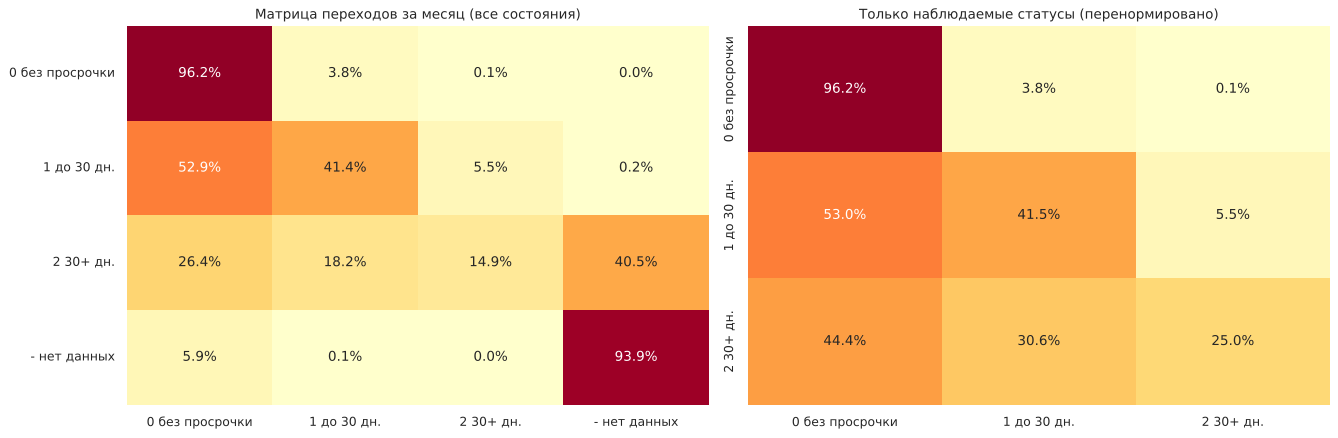

,0 без просрочки,1 до 30 дн.,2 30+ дн.,- нет данных
0 без просрочки,2386420,93422,1408,716
1 до 30 дн.,84491,66058,8788,354
2 30+ дн.,3183,2195,1796,4892
- нет данных,243044,5463,567,3865155


In [6]:
STATES = ["0 без просрочки", "1 до 30 дн.", "2 30+ дн.", "- нет данных"]
code = {"0": 0, "1": 1, "2": 2, "-": 3}
strings = obligations.payment_string.fillna("").str.ljust(25, "-").str[:25]
A = np.array([[code[ch] for ch in s] for s in strings], dtype=np.int8)
src_state, dst_state = (
    A[:, 1:].ravel(),
    A[:, :-1].ravel(),
)  # позиция k+1 — более ранний месяц
counts = pd.crosstab(pd.Series(src_state, name="из"), pd.Series(dst_state, name="в"))
counts.index, counts.columns = STATES, STATES
P_full = counts.div(counts.sum(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(
    P_full, annot=True, fmt=".1%", cmap="YlOrRd", vmin=0, vmax=1, ax=axes[0], cbar=False
)
axes[0].set_title("Матрица переходов за месяц (все состояния)")
P = P_full.iloc[:3, :3]
P = P.div(P.sum(axis=1), axis=0)
sns.heatmap(
    P, annot=True, fmt=".1%", cmap="YlOrRd", vmin=0, vmax=1, ax=axes[1], cbar=False
)
axes[1].set_title("Только наблюдаемые статусы (перенормировано)")
plt.tight_layout()
plt.show()
display(counts)

**Как читать матрицу.**
* Из «без просрочки» кредит остаётся там же в ~96% случаев — это норма портфеля.
* Из «до 30 дней» больше половины **выздоравливает** за месяц (cure rate), ~6% уходит глубже — короткая просрочка часто техническая.
* Из «30+» выздоравливают лишь ~26%, а ~40% строк дальше **обрываются** («нет данных»: кредит продан, списан, закрыт через суд). 30+ — состояние, из которого кредит в норму почти не возвращается.

Отсюда **определение дефолта**: для таргета берём 90+ дней (стандарт Базеля / МСФО 9), а **ранним сигналом** в признаках — 30+: это точка, после которой вероятность вернуться в норму резко падает.

### Веса состояний: вероятность «докатиться» до 30+
Делаем состояние «30+» поглощающим и возводим матрицу в степень: строка `(P^k)[s, 30+]` — вероятность, что кредит из состояния `s` хотя бы раз окажется в 30+ за `k` месяцев.

In [7]:
Pa = P.to_numpy().copy()
Pa[2] = [0, 0, 1]
horizons = [1, 3, 6, 12]
reach = pd.DataFrame(
    {f"{k} мес.": np.linalg.matrix_power(Pa, k)[:, 2] for k in horizons},
    index=STATES[:3],
)
display(reach.round(4))
p12 = np.linalg.matrix_power(Pa, 12)[:, 2]
severity_30p = p12[2] / p12[1]
severity_0 = p12[0] / p12[1]
print(
    f"P(30+ за 12 мес.): из нормы {p12[0]:.1%}, из «до 30» {p12[1]:.1%}, из «30+» 100%"
)
print(
    f"Тяжесть «30+» относительно «до 30»: {severity_30p:.2f}; «нормы» — {severity_0:.2f} (фон, берём 0)"
)

P(30+ за 12 мес.): из нормы 4.1%, из «до 30» 12.5%, из «30+» 100%
Тяжесть «30+» относительно «до 30»: 7.99; «нормы» — 0.32 (фон, берём 0)


,1 мес.,3 мес.,6 мес.,12 мес.
0 без просрочки,0.0006,0.0066,0.0178,0.0405
1 до 30 дн.,0.0552,0.0893,0.1042,0.1251
2 30+ дн.,1,1,1,1


Если нормировать на состояние «до 30 дней», то месяц в 30+ «весит» примерно в 8 раз больше. Месяц без просрочки — фоновый риск, который и так есть у всех, вес 0.

### Затухание: насколько давняя просрочка ещё что-то значит
Для каждой позиции `k` строки считаем лог-лифт дефолта: `ln(bad rate компаний с просрочкой в месяце k / bad rate без неё)`. Чем давнее просрочка, тем слабее связь. Подгоняем экспоненту `lift_k ≈ c·d^k` взвешенным МНК (вес √числа компаний с просрочкой в месяце `k`: давние месяцы шумнее).

Затухание за месяц: 0.914 — сигнал вдвое слабеет за 7.7 мес.


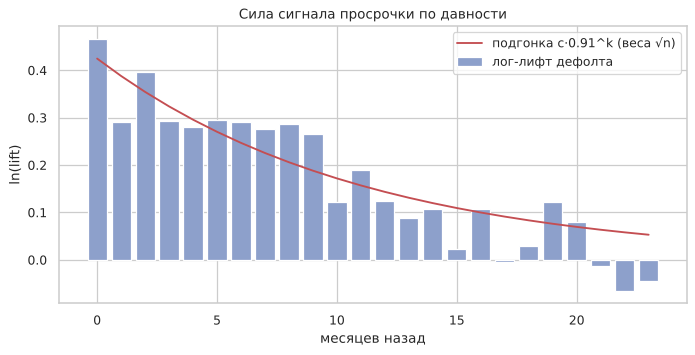

In [8]:
y_by_company = feats.set_index("company_key").target
from scipy.optimize import curve_fit

lifts, n_k = [], []
for k in range(24):
    has = (
        pd.Series((A[:, k] == 1) | (A[:, k] == 2))
        .groupby(obligations.company_key.values)
        .max()
    )
    yy = y_by_company.loc[has.index]
    lifts.append(np.log(yy[has].mean() / yy[~has].mean()))
    n_k.append(int(has.sum()))
lifts, n_k, k = np.array(lifts), np.array(n_k), np.arange(24)
# взвешенный МНК: у давних месяцев меньше наблюдений — их точки шумнее
(c0, decay), _ = curve_fit(
    lambda k, c, d: c * d**k, k, lifts, p0=(0.5, 0.9), sigma=1 / np.sqrt(n_k)
)
decay = float(decay)
plt.figure(figsize=(9, 4))
plt.bar(k, lifts, color="#8da0cb", label="лог-лифт дефолта")
plt.plot(k, c0 * decay**k, "r-", label=f"подгонка c·{decay:.2f}^k (веса √n)")
plt.xlabel("месяцев назад")
plt.ylabel("ln(lift)")
plt.legend()
plt.title("Сила сигнала просрочки по давности")
plt.show()
print(
    f"Затухание за месяц: {decay:.3f} — сигнал вдвое слабеет за {np.log(0.5) / np.log(decay):.1f} мес."
)

Сигнал просрочки вдвое слабеет примерно за полгода–год: просрочка в прошлом месяце важнее, чем два года назад, — это интуиция кредитного аналитика, теперь в числах.

### Индекс просрочек и проверка весов
Итоговый признак: `bki_delinquency_index = Σ_кредиты Σ_k тяжесть(статус_k) · d^k` за 24 месяца. Проверяем, что веса из матрицы лучше «наивных» (все просрочки по 1, без затухания), — сравниваем Gini однофакторно.

In [9]:
def delinquency_gini(sev2, dec):
    W = np.select([A == 1, A == 2], [1.0, sev2], 0.0)[:, :24] * dec ** np.arange(24)
    idx = (
        pd.Series(W.sum(axis=1))
        .groupby(obligations.company_key.values)
        .sum()
        .reindex(y_by_company.index)
        .fillna(0)
    )
    return sl.gini(y_by_company, idx)


grid = pd.DataFrame(
    [
        [delinquency_gini(s, d) for d in (1.0, 0.95, F.RECENCY_DECAY, 0.8)]
        for s in (1.0, 2.6, F.SEVERITY["2"], 11.0)
    ],
    index=pd.Index([1.0, 2.6, F.SEVERITY["2"], 11.0], name="вес 30+"),
    columns=pd.Index([1.0, 0.95, F.RECENCY_DECAY, 0.8], name="затухание"),
)
display(grid.round(4))
print(
    "Наивный индекс (1; 1):",
    round(grid.iloc[0, 0], 4),
    "→ из матрицы:",
    round(grid.loc[F.SEVERITY["2"], F.RECENCY_DECAY], 4),
)
print("Константы в app.credit.features:", F.SEVERITY, F.RECENCY_DECAY)
print(f"Из данных: тяжесть {severity_30p:.2f}, затухание {decay:.3f}")
assert (
    abs(F.SEVERITY["2"] - severity_30p) < 0.3 and abs(F.RECENCY_DECAY - decay) < 0.03
), "пересчитайте константы в features.py"

Наивный индекс (1; 1): 0.0486 → из матрицы: 0.0641
Константы в app.credit.features: {'0': 0.0, '1': 1.0, '2': 8.0, '-': 0.0} 0.9
Из данных: тяжесть 7.99, затухание 0.914


затухание,1.0,0.95,0.9,0.8
вес 30+,,,,
1.0,0.0486,0.0532,0.0561,0.0591
2.6,0.0528,0.0572,0.0597,0.0622
8.0,0.0578,0.0619,0.0641,0.0654
11.0,0.0589,0.0628,0.0649,0.0661


Веса из матрицы дают прирост Gini индекса примерно на треть к наивной сумме, а дальнейшее «подкручивание» (вес 11, затухание 0,8) почти ничего не добавляет и рискует переобучиться. Фиксируем **тяжесть 0 / 1 / 8 и затухание 0,9** — эти константы зашиты в `src/app/credit/features.py` (проверка `assert` выше), поэтому в конвейере признак считается так же, как при обучении.

## 4. Разбиение выборки

* **OOT** (out-of-time) — заявки с 01.04.2025: проверка на «будущем», которого модель не видела.
* Остальное — случайно 75/25 на **train** и **valid** со стратификацией по таргету.

Сегмент присваивается по тем же правилам, что будут лежать в `scoring_segments` (раздел 7), — проверяем модели ровно на тех клиентах, к кому они будут применяться.

In [10]:
OOT_FROM = pd.Timestamp("2025-04-01")
SEGMENT_RULES = [
    {
        "code": "new_business",
        "priority": 10,
        "name": "Молодой бизнес / без кредитной истории",
        "description": "Возраст бизнеса < 12 мес. или нет ни одного кредита в БКИ: КИ и обороты короткие, модель на бизнес-признаках.",
        "conditions": {
            "any": [
                {"feature": "company_age_months", "op": "<", "value": 12},
                {"feature": "bki_loans_cnt", "op": "==", "value": 0},
            ]
        },
    },
    {
        "code": "ip_micro",
        "priority": 20,
        "name": "ИП и микропредприятия",
        "description": "ИП любого размера и микропредприятия ЮЛ с историей от 12 мес.",
        "conditions": {
            "any": [
                {"feature": "legal_form", "op": "==", "value": "ИП"},
                {"feature": "msp_category", "op": "==", "value": "micro"},
            ]
        },
    },
    {
        "code": "sme",
        "priority": 30,
        "name": "Малые и средние ЮЛ",
        "description": "ООО/АО категорий small и medium с историей от 12 мес.",
        "conditions": {
            "all": [
                {"feature": "legal_form", "op": "==", "value": "ЮЛ"},
                {"feature": "msp_category", "op": "in", "value": ["small", "medium"]},
            ]
        },
    },
    {
        "code": "all",
        "priority": 100,
        "name": "Все остальные (запасная модель)",
        "description": "Подходит всем: применяется, если ни один сегмент выше не подошёл или его модель отключена.",
        "conditions": {},
    },
]
segments = [
    SC.Segment(r["code"], r["priority"], r["conditions"]) for r in SEGMENT_RULES
]
FEATURE_COLS = list(F.FEATURE_CATALOG)


def to_facts(row) -> dict:
    return {c: (None if pd.isna(row[c]) else row[c]) for c in FEATURE_COLS}


pop["segment"] = [SC.match_segment(segments, to_facts(r)) for _, r in pop.iterrows()]
pop["sample"] = "train"
pop.loc[pop.as_of_date >= OOT_FROM, "sample"] = "oot"
dev_idx = pop.index[pop["sample"] != "oot"]
_, valid_idx = train_test_split(
    dev_idx,
    test_size=0.25,
    stratify=pop.loc[dev_idx, "target"],
    random_state=RANDOM_STATE,
)
pop.loc[valid_idx, "sample"] = "valid"
display(
    pd.crosstab(
        pop.segment, pop["sample"], values=pop.target, aggfunc=["size", "mean"]
    ).round(3)
)

size                mean              
sample         oot  train valid    oot  train  valid
segment                                             
ip_micro      4612  15778  5180  0.041  0.045  0.047
new_business   936   3297  1135  0.069  0.076  0.080
sme           1626   5396  1842  0.044  0.047  0.038

## 5. Биннинг, WoE и IV

**Зачем биннинг.** Сырые значения связаны с риском нелинейно (оборот, возраст), с выбросами и пропусками. Бины решают всё сразу: пропуск — отдельный бин, выбросы попадают в крайний бин, а WoE превращает любую форму зависимости в линейную для логрега.

**Правила биннинга** (`ml/scorecard_lib.py`):
* числовые — старт с ~16 квантильных бинов, затем слияние соседних, пока bad rate не станет **монотонным** (направление — по знаку корреляции Спирмена) и в каждом бине не будет ≥ 5% выборки и ≥ 5 дефолтов. Монотонность — требование объяснимости: «чем больше просрочек, тем меньше баллов», без зубцов;
* категориальные — редкие категории (< 5% или < 5 дефолтов) → «прочие», затем слияние соседних по bad rate групп до ≤ 6. Новая категория в проде попадает в бин «прочие».

**WoE** бина `= ln(%хороших / %плохих)`, **IV** признака `= Σ (%хороших − %плохих)·WoE` — мера разделяющей силы: < 0,02 — нет связи, 0,02–0,1 — слабая, 0,1–0,3 — средняя, > 0,3 — сильная, > 0,5 — подозрительно (проверить на утечку).

,feature,iv,bins,strength,название
0,turnover_cv,0.4097,5,сильная,Волатильность оборотов
1,okved_section,0.2532,6,средняя,Раздел ОКВЭД основного вида деятельности
2,balance_to_inflow,0.1798,8,средняя,Остаток к месячному обороту
3,bki_history_months,0.156,6,средняя,"Длина кредитной истории, мес."
4,company_age_months,0.1368,6,средняя,"Возраст бизнеса, мес."
5,fssp_active_cnt,0.1006,2,средняя,Открытых исп. производств
6,net_margin,0.097,5,слабая,Чистый денежный поток к обороту
7,fssp_amount_ratio,0.0869,2,слабая,Долг ФССП к месячному обороту
8,region_code,0.0662,6,слабая,Регион регистрации
9,tax_debt_ratio,0.0612,2,слабая,Налоговый долг к месячному обороту


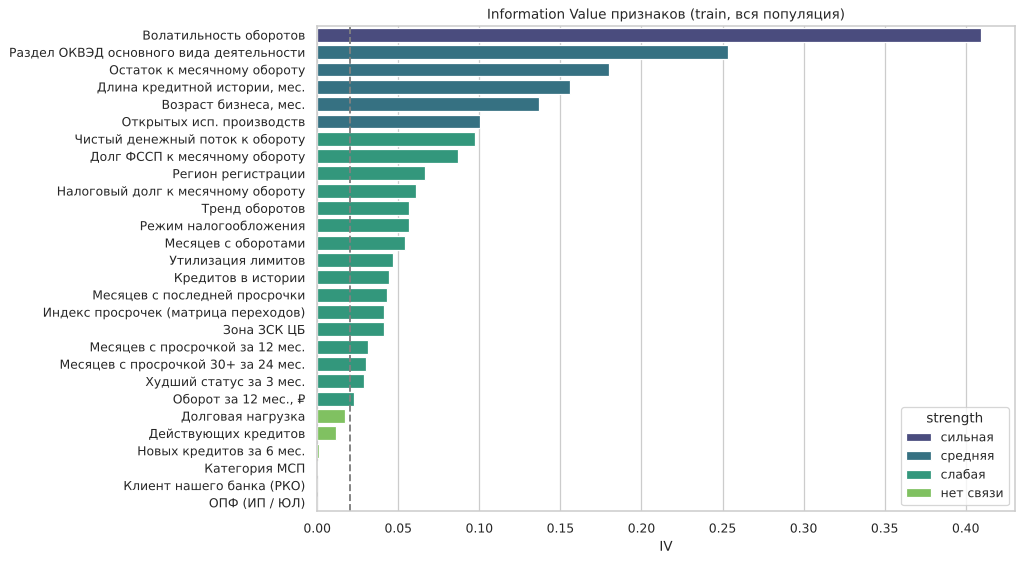

In [11]:
CATEGORICAL = {
    "legal_form",
    "msp_category",
    "okved_section",
    "region_code",
    "tax_regime",
    "zsk_zone",
}
train_all = pop[pop["sample"] == "train"]
binnings_all = sl.auto_bin(train_all, train_all.target, FEATURE_COLS, CATEGORICAL)
iv_all = sl.iv_summary(binnings_all)
iv_all["название"] = iv_all.feature.map(lambda f: F.FEATURE_CATALOG[f][0])
display(iv_all.round(4))

plt.figure(figsize=(10, 7))
sns.barplot(
    data=iv_all, y="название", x="iv", hue="strength", dodge=False, palette="viridis"
)
plt.axvline(0.02, ls="--", color="grey")
plt.title("Information Value признаков (train, вся популяция)")
plt.xlabel("IV")
plt.ylabel("")
plt.show()

Пример бинов: у сильных признаков bad rate монотонен, WoE плавно меняет знак.

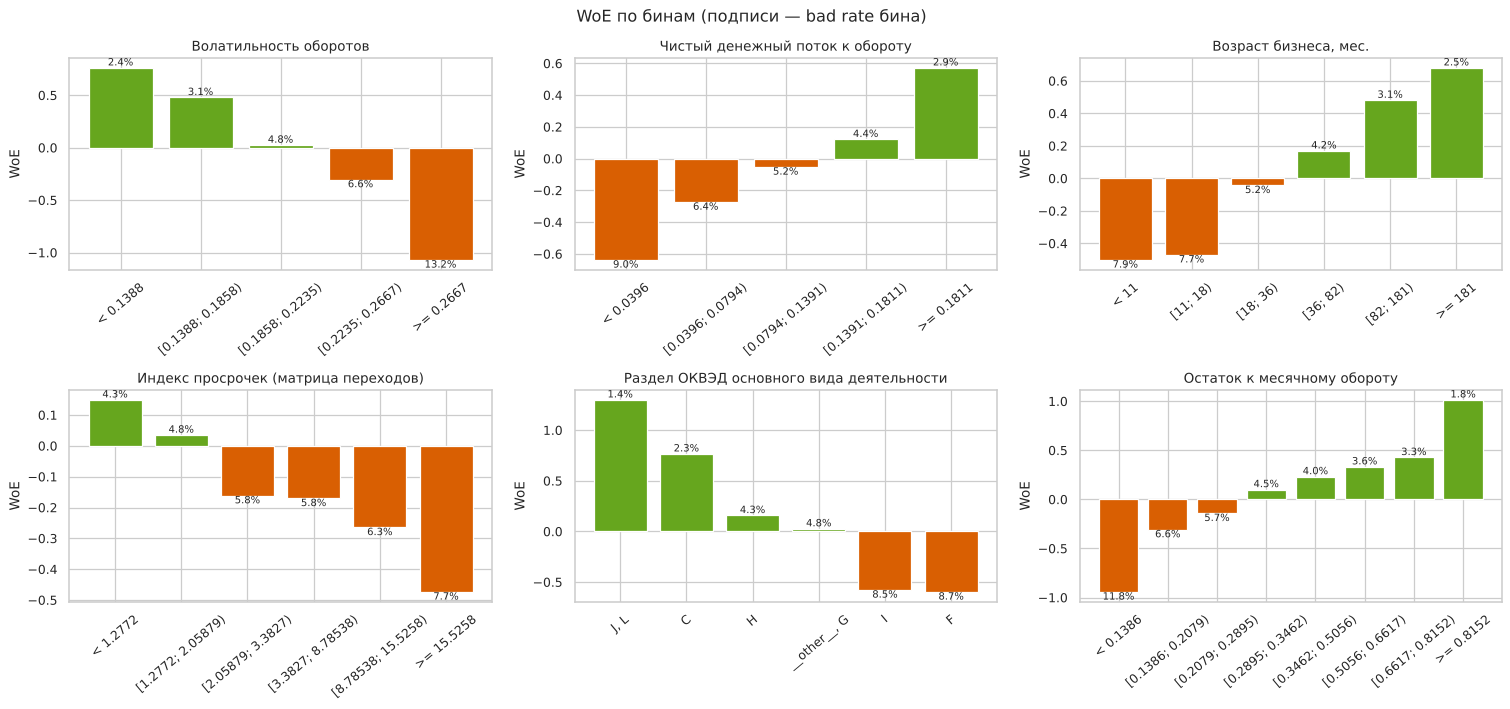

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, f in zip(
    axes.ravel(),
    [
        "turnover_cv",
        "net_margin",
        "company_age_months",
        "bki_delinquency_index",
        "okved_section",
        "balance_to_inflow",
    ],
):
    d = binnings_all[f].describe()
    ax.bar(
        d["bin"].astype(str),
        d["woe"],
        color=np.where(d["woe"] >= 0, "#66a61e", "#d95f02"),
    )
    for i, (w, br) in enumerate(zip(d["woe"], d["bad_rate"])):
        ax.text(
            i, w, f"{br:.1%}", ha="center", va="bottom" if w >= 0 else "top", fontsize=8
        )
    ax.set_title(f"{F.FEATURE_CATALOG[f][0]}")
    ax.tick_params(axis="x", rotation=40)
    ax.set_ylabel("WoE")
plt.suptitle("WoE по бинам (подписи — bad rate бина)")
plt.tight_layout()
plt.show()

## 6. Модели

**Отбор признаков** для каждой модели одинаковый и воспроизводимый:
1. IV ≥ 0,02 на train сегмента;
2. фильтр корреляции WoE: при |ρ| > 0,7 оставляем признак с бо́льшим IV (например, `bki_dpd_months_12m` и `bki_delinquency_index` — почти одно и то же);
3. пошаговая логистическая регрессия на WoE: исключаем признаки с **неверным знаком** коэффициента (вклад противоречит WoE — признак мешает другим) и **незначимые** (p > 0,05);
4. контроль мультиколлинеарности VIF < 5.

**Веса признаков.** Вес признака в скоркарте — коэффициент β логрега на WoE. Бин получает баллы `−Factor·β·WoE`, где Factor = PDO / ln 2 = 28,85: удвоение шансов «хороший:плохой» = +20 баллов, 600 баллов ↔ шансы 50:1. Относительная важность признака — доля в разбросе баллов: `|β|·std(WoE)`.

In [13]:
def develop_scorecard(name, seg_codes, feature_pool, min_share=0.05, max_bins=8):
    seg = pop[pop.segment.isin(seg_codes)]
    tr, va, oot = (seg[seg["sample"] == s] for s in ("train", "valid", "oot"))
    binn = sl.auto_bin(
        tr, tr.target, feature_pool, CATEGORICAL, min_share=min_share, max_bins=max_bins
    )
    ivs = sl.iv_summary(binn).set_index("feature")["iv"]
    log = [f"{f}: IV={v:.3f} < 0.02 — исключён" for f, v in ivs.items() if v < 0.02]
    cand = [f for f, v in ivs.items() if v >= 0.02]
    W_tr = pd.DataFrame({f: binn[f].transform(tr[f]) for f in cand}, index=tr.index)
    cand, log_c = sl.correlation_filter(W_tr, ivs[cand])
    chosen, log_s = sl.stepwise_select(W_tr, tr.target, cand)
    model, stats = sl.logit_fit(W_tr[chosen], tr.target)
    vifs = sl.vif(W_tr[chosen])
    alpha, betas = float(model.intercept_[0]), dict(zip(chosen, model.coef_[0]))
    base_score = SC.OFFSET - SC.FACTOR * alpha
    bins = [b for f in chosen for b in binn[f].bins_export(betas[f])]
    card = SC.Scorecard(
        model_id=name,
        base_score=round(base_score, 2),
        bins=[
            SC.Bin(
                b["feature"],
                b["order"],
                b["points"],
                b["woe"],
                b["lower"],
                b["upper"],
                tuple(b["categories"]) if b["categories"] else None,
                b["is_missing"],
            )
            for b in bins
        ],
    )

    def scores(df):
        return np.array([SC.score(card, to_facts(r)).score for _, r in df.iterrows()])

    s_tr, s_va, s_oot = scores(tr), scores(va), scores(oot)
    importance = pd.Series({f: abs(betas[f]) * W_tr[f].std() for f in chosen})
    report = pd.DataFrame(
        {
            "название": [F.FEATURE_CATALOG[f][0] for f in chosen],
            "IV": ivs[chosen].round(4).values,
            "β": [round(betas[f], 4) for f in chosen],
            "p-value": stats.loc[chosen, "p_value"].round(4).values,
            "VIF": vifs[chosen].round(2).values,
            "вес, %": (importance / importance.sum() * 100).round(1).values,
        },
        index=chosen,
    ).sort_values("вес, %", ascending=False)
    return {
        "name": name,
        "segments": seg_codes,
        "card": card,
        "bins": bins,
        "chosen": chosen,
        "betas": betas,
        "alpha": alpha,
        "ivs": ivs,
        "binnings": binn,
        "report": report,
        "log": log + log_c + log_s,
        "data": {"train": (tr, s_tr), "valid": (va, s_va), "oot": (oot, s_oot)},
    }


def metrics(dev):
    rows = {}
    for part, (df, s) in dev["data"].items():
        rows[part] = {
            "n": len(df),
            "bad": int(df.target.sum()),
            "Gini": sl.gini(df.target, -s),
            "KS": sl.ks(df.target, -s),
        }
    out = pd.DataFrame(rows).T
    out["PSI vs train"] = [
        0.0,
        sl.psi(dev["data"]["train"][1], dev["data"]["valid"][1]),
        sl.psi(dev["data"]["train"][1], dev["data"]["oot"][1]),
    ]
    return out


BKI = [f for f in FEATURE_COLS if f.startswith("bki_")]
BUSINESS = [f for f in FEATURE_COLS if f not in BKI]
POOL_ALL = [f for f in FEATURE_COLS if f != "zsk_zone"] + ["zsk_zone"]

### 6.1 Общая скоркарта `msb_general` (вся популяция)
Базовая модель и запасной вариант для сегмента `all`. С ней сравниваем сегментные.

In [14]:
dev_general = develop_scorecard(
    "msb_general", ["new_business", "ip_micro", "sme", "all"], POOL_ALL
)
print("\n".join(dev_general["log"]))
display(dev_general["report"])
display(metrics(dev_general).round(4))

debt_burden: IV=0.017 < 0.02 — исключён
bki_active_cnt: IV=0.012 < 0.02 — исключён
bki_new_loans_6m: IV=0.001 < 0.02 — исключён
msp_category: IV=0.001 < 0.02 — исключён
own_bank_client: IV=0.000 < 0.02 — исключён
legal_form: IV=0.000 < 0.02 — исключён
fssp_amount_ratio: |ρ|=0.80 с fssp_active_cnt (IV выше) — исключён
bki_dpd_months_12m: |ρ|=0.92 с bki_delinquency_index (IV выше) — исключён
bki_worst_status_3m: |ρ|=0.82 с bki_months_since_dpd (IV выше) — исключён
turnover_months: неверный знак β=+0.136 — исключён
turnover_trend: неверный знак β=+0.008 — исключён
company_age_months: незначим (p=0.752) — исключён


,название,IV,β,p-value,VIF,"вес, %"
bki_history_months,"Длина кредитной истории, мес.",0.156,-1.199,0,1.78,13.9
okved_section,Раздел ОКВЭД основного вида деятельности,0.2532,-0.8461,0,1.05,13.7
turnover_cv,Волатильность оборотов,0.4097,-0.6199,0,1.14,10.4
region_code,Регион регистрации,0.0662,-1.053,0,1,7.6
bki_delinquency_index,Индекс просрочек (матрица переходов),0.0412,-1.21,0.0001,3.72,6.7
balance_to_inflow,Остаток к месячному обороту,0.1798,-0.5611,0,1.07,6.6
tax_regime,Режим налогообложения,0.0566,-0.9434,0,1.01,6
bki_months_since_dpd,Месяцев с последней просрочки,0.0432,-1.038,0,2.09,5.8
bki_utilization,Утилизация лимитов,0.047,-0.9384,0,1.06,5.3
net_margin,Чистый денежный поток к обороту,0.097,-0.5782,0,1.05,5.2


,n,bad,Gini,KS,PSI vs train
train,2.447e+04,1212,0.575,0.4371,0
valid,8157,404,0.5611,0.4298,0.0015
oot,7174,324,0.534,0.404,0.0013


### 6.2 `msb_new_business` — молодой бизнес и компании без КИ
Выборка в разы меньше общей, поэтому бины крупнее (≥ 8% выборки, до 5 бинов): лучше грубая, но устойчивая карта, чем детальная и переобученная.

In [15]:
dev_new = develop_scorecard(
    "msb_new_business", ["new_business"], POOL_ALL, min_share=0.08, max_bins=5
)
print("\n".join(dev_new["log"]))
display(dev_new["report"])
display(metrics(dev_new).round(4))

net_margin: IV=0.014 < 0.02 — исключён
turnover_months: IV=0.006 < 0.02 — исключён
company_age_months: IV=0.006 < 0.02 — исключён
debt_burden: IV=0.005 < 0.02 — исключён
revenue_12m: IV=0.005 < 0.02 — исключён
bki_new_loans_6m: IV=0.005 < 0.02 — исключён
legal_form: IV=0.003 < 0.02 — исключён
bki_loans_cnt: IV=0.003 < 0.02 — исключён
msp_category: IV=0.002 < 0.02 — исключён
own_bank_client: IV=0.001 < 0.02 — исключён
bki_utilization: IV=0.001 < 0.02 — исключён
bki_history_months: IV=0.000 < 0.02 — исключён
bki_active_cnt: IV=0.000 < 0.02 — исключён
fssp_amount_ratio: IV=0.000 < 0.02 — исключён
fssp_active_cnt: IV=0.000 < 0.02 — исключён
tax_debt_ratio: IV=0.000 < 0.02 — исключён
bki_delinquency_index: IV=0.000 < 0.02 — исключён
bki_worst_status_3m: IV=0.000 < 0.02 — исключён
bki_dpd_months_12m: IV=0.000 < 0.02 — исключён
bki_dpd30_months_24m: IV=0.000 < 0.02 — исключён
turnover_trend: неверный знак β=+0.023 — исключён
bki_months_since_dpd: незначим (p=0.189) — исключён
zsk_zone: незнач

,название,IV,β,p-value,VIF,"вес, %"
balance_to_inflow,Остаток к месячному обороту,0.6102,-0.7597,0,1.22,36.8
turnover_cv,Волатильность оборотов,0.4908,-0.5912,0,1.23,23.1
okved_section,Раздел ОКВЭД основного вида деятельности,0.0984,-1,0,1.01,18.1
tax_regime,Режим налогообложения,0.0583,-0.886,0.0016,1,13
region_code,Регион регистрации,0.0207,-1.014,0.0349,1,9


,n,bad,Gini,KS,PSI vs train
train,3297,251,0.5062,0.3957,0
valid,1135,91,0.5729,0.472,0.0009
oot,936,65,0.5417,0.4099,0.0091


### 6.3 `msb_ip_micro` — ИП и микропредприятия

In [16]:
dev_ip = develop_scorecard("msb_ip_micro", ["ip_micro"], POOL_ALL)
print("\n".join(dev_ip["log"]))
display(dev_ip["report"])
display(metrics(dev_ip).round(4))

bki_loans_cnt: IV=0.020 < 0.02 — исключён
bki_active_cnt: IV=0.007 < 0.02 — исключён
own_bank_client: IV=0.001 < 0.02 — исключён
msp_category: IV=0.000 < 0.02 — исключён
legal_form: IV=0.000 < 0.02 — исключён
turnover_months: IV=0.000 < 0.02 — исключён
fssp_amount_ratio: |ρ|=0.74 с fssp_active_cnt (IV выше) — исключён
bki_months_since_dpd: |ρ|=0.79 с bki_delinquency_index (IV выше) — исключён
bki_dpd_months_12m: |ρ|=0.93 с bki_delinquency_index (IV выше) — исключён
bki_worst_status_3m: |ρ|=0.76 с bki_delinquency_index (IV выше) — исключён
turnover_trend: неверный знак β=+0.376 — исключён
company_age_months: незначим (p=0.468) — исключён
bki_utilization: незначим (p=0.120) — исключён
zsk_zone: незначим (p=0.070) — исключён
net_margin: незначим (p=0.051) — исключён


,название,IV,β,p-value,VIF,"вес, %"
bki_history_months,"Длина кредитной истории, мес.",0.1445,-1.401,0,1.17,16.4
turnover_cv,Волатильность оборотов,0.5198,-0.667,0,1.18,13.9
okved_section,Раздел ОКВЭД основного вида деятельности,0.2251,-0.7432,0,1.08,11.9
bki_delinquency_index,Индекс просрочек (матрица переходов),0.0914,-1.31,0,1.73,11.8
region_code,Регион регистрации,0.0794,-1.064,0,1,9
tax_regime,Режим налогообложения,0.0902,-0.9811,0,1,8.3
fssp_active_cnt,Открытых исп. производств,0.2176,-0.5491,0,1.08,6.5
tax_debt_ratio,Налоговый долг к месячному обороту,0.1283,-0.542,0,1.05,4.8
revenue_12m,"Оборот за 12 мес., ₽",0.0557,-0.5314,0.002,1.06,3.8
bki_new_loans_6m,Новых кредитов за 6 мес.,0.0273,-0.8052,0.0008,1.05,3.8


,n,bad,Gini,KS,PSI vs train
train,1.578e+04,710,0.5908,0.4561,0
valid,5180,243,0.56,0.4309,0.0008
oot,4612,187,0.5415,0.4269,0.0018


### 6.4 `msb_sme` — малые и средние ЮЛ

In [17]:
dev_sme = develop_scorecard("msb_sme", ["sme"], POOL_ALL, min_share=0.06, max_bins=6)
print("\n".join(dev_sme["log"]))
display(dev_sme["report"])
display(metrics(dev_sme).round(4))

bki_new_loans_6m: IV=0.014 < 0.02 — исключён
bki_active_cnt: IV=0.005 < 0.02 — исключён
tax_regime: IV=0.004 < 0.02 — исключён
own_bank_client: IV=0.004 < 0.02 — исключён
msp_category: IV=0.000 < 0.02 — исключён
legal_form: IV=0.000 < 0.02 — исключён
fssp_amount_ratio: IV=0.000 < 0.02 — исключён
tax_debt_ratio: IV=0.000 < 0.02 — исключён
fssp_active_cnt: IV=0.000 < 0.02 — исключён
turnover_months: IV=0.000 < 0.02 — исключён
bki_months_since_dpd: |ρ|=0.82 с bki_delinquency_index (IV выше) — исключён
bki_dpd_months_12m: |ρ|=0.91 с bki_delinquency_index (IV выше) — исключён
bki_worst_status_3m: |ρ|=0.81 с bki_delinquency_index (IV выше) — исключён
company_age_months: неверный знак β=+0.129 — исключён
turnover_trend: незначим (p=0.999) — исключён
revenue_12m: незначим (p=0.584) — исключён
bki_dpd30_months_24m: незначим (p=0.520) — исключён
debt_burden: незначим (p=0.454) — исключён


,название,IV,β,p-value,VIF,"вес, %"
net_margin,Чистый денежный поток к обороту,0.6716,-0.6708,0,1.33,17.4
bki_delinquency_index,Индекс просрочек (матрица переходов),0.0833,-1.884,0,1.24,15.3
okved_section,Раздел ОКВЭД основного вида деятельности,0.1856,-0.9673,0,1.07,12.4
bki_loans_cnt,Кредитов в истории,0.0705,-1.502,0,1.38,12.2
bki_history_months,"Длина кредитной истории, мес.",0.1645,-0.9323,0,1.27,11.9
bki_utilization,Утилизация лимитов,0.3293,-0.5544,0,1.26,8.4
region_code,Регион регистрации,0.0799,-0.9934,0,1,8.2
balance_to_inflow,Остаток к месячному обороту,0.2628,-0.3503,0.017,1.2,5.3
turnover_cv,Волатильность оборотов,0.1053,-0.5471,0.0122,1.07,5.1
zsk_zone,Зона ЗСК ЦБ,0.0883,-0.5842,0.0029,1.02,3.9


,n,bad,Gini,KS,PSI vs train
train,5396,251,0.6175,0.4744,0
valid,1842,70,0.5386,0.4142,0.0071
oot,1626,72,0.4949,0.3909,0.0108


### 6.5 Challenger: градиентный бустинг
GBM на сырых признаках ловит нелинейности и взаимодействия, которые скоркарта пропускает. В проде он не принимает решений (его баллы труднее объяснить клиенту и регулятору), но служит **ориентиром**: если бустинг сильно лучше, в скоркарте не хватает признаков или взаимодействий.

In [18]:
gbm_cols = [c for c in POOL_ALL]


def gbm_frame(df):
    X = df[gbm_cols].copy()
    for c in CATEGORICAL:
        X[c] = X[c].astype("category")
    return X


tr_g = pop[pop["sample"] == "train"]
gbm = HistGradientBoostingClassifier(
    max_depth=3,
    learning_rate=0.05,
    max_iter=300,
    min_samples_leaf=80,
    l2_regularization=1.0,
    categorical_features="from_dtype",
    random_state=RANDOM_STATE,
)
gbm.fit(gbm_frame(tr_g), tr_g.target)
gbm_rows = {}
for part in ("train", "valid", "oot"):
    d = pop[pop["sample"] == part]
    p = gbm.predict_proba(gbm_frame(d))[:, 1]
    gbm_rows[part] = {
        "n": len(d),
        "bad": int(d.target.sum()),
        "Gini": sl.gini(d.target, p),
        "KS": sl.ks(d.target, p),
    }
gbm_metrics = pd.DataFrame(gbm_rows).T
display(gbm_metrics.round(4))

,n,bad,Gini,KS
train,2.447e+04,1212,0.7141,0.5626
valid,8157,404,0.5433,0.4054
oot,7174,324,0.559,0.4363


## 7. Валидация и выбор чемпиона по сегментам

Для каждого сегмента сравниваем на отложенных данных этого сегмента — valid, OOT и их объединении (**holdout**: в маленьких сегментах в одном OOT всего десятки дефолтов, Gini по нему шумит на ±0,1) — общую карту, сегментную карту и бустинг. Правило:
* сегментная модель становится **champion** сегмента, если её Gini на holdout выше общей хотя бы на 0,02 и она не деградирует от valid к OOT больше чем на 0,10;
* иначе сегмент **отключается** (`is_active = false`) и его клиентов обслуживает общая модель через сегмент `all`; сегментная модель остаётся в БД как `challenger` для мониторинга.

Так правила выбора модели в БД — результат сравнения, а не вкуса.

In [19]:
devs = {"new_business": dev_new, "ip_micro": dev_ip, "sme": dev_sme}


def seg_gini(dev, seg, parts):
    df = pd.concat([dev["data"][p][0] for p in parts])
    s = np.concatenate([dev["data"][p][1] for p in parts])
    m = (df.segment == seg).to_numpy()
    return (
        sl.gini(df.target[m], -s[m])
        if m.sum() and df.target[m].nunique() == 2
        else np.nan
    )


def gbm_seg_gini(seg, parts):
    d = pop[pop["sample"].isin(parts) & (pop.segment == seg)]
    return sl.gini(d.target, gbm.predict_proba(gbm_frame(d))[:, 1])


compare = []
for seg, dev in devs.items():
    row = {
        "сегмент": seg,
        "дефолтов в holdout": int(
            pop[(pop.segment == seg) & (pop["sample"] != "train")].target.sum()
        ),
    }
    for label, parts in (
        ("valid", ["valid"]),
        ("oot", ["oot"]),
        ("holdout", ["valid", "oot"]),
    ):
        row[f"общая {label}"] = seg_gini(dev_general, seg, parts)
        row[f"сегментная {label}"] = seg_gini(dev, seg, parts)
        row[f"GBM {label}"] = gbm_seg_gini(seg, parts)
    row["прирост holdout"] = row["сегментная holdout"] - row["общая holdout"]
    row["деградация valid→OOT"] = row["сегментная valid"] - row["сегментная oot"]
    row["решение"] = (
        "сегментная — champion"
        if row["прирост holdout"] >= 0.02 and row["деградация valid→OOT"] <= 0.10
        else "общая (сегмент выключен)"
    )
    compare.append(row)
compare = pd.DataFrame(compare).set_index("сегмент")
display(compare.round(4))

,дефолтов в holdout,общая valid,сегментная valid,GBM valid,общая oot,сегментная oot,GBM oot,общая holdout,сегментная holdout,GBM holdout,прирост holdout,деградация valid→OOT,решение
сегмент,,,,,,,,,,,,,
new_business,156,0.5645,0.5729,0.5555,0.503,0.5417,0.5696,0.5392,0.5598,0.5621,0.0206,0.0311,сегментная — champion
ip_micro,430,0.5615,0.56,0.5436,0.538,0.5415,0.5599,0.5515,0.5518,0.5518,0.0003,0.0185,общая (сегмент выключен)
sme,142,0.4942,0.5386,0.4815,0.4989,0.4949,0.502,0.4933,0.5138,0.4901,0.0205,0.0437,сегментная — champion


**Результат сравнения.**
* `new_business` — сегментная карта лучше общей: у молодых компаний КИ почти пустая, а общая модель тратит 30–40% веса на признаки КИ. Сегментная карта строится на остатках, волатильности, отрасли и налоговом режиме — тем, что у молодого бизнеса есть. → **champion**.
* `sme` — сегментная карта лучше: у малых и средних ЮЛ ключевой драйвер — маржа и утилизация лимитов, а волатильность (главный признак общей модели) почти не работает. → **champion**.
* `ip_micro` — прироста нет: этот сегмент — почти две трети популяции, общая модель и так «подстроена» под него. Сегмент выключен, его обслуживает общая модель; `msb_ip_micro` остаётся challenger'ом.

Прирост скромный (+0,02 Gini), это нормально для скоркарт: сегментация дорога в сопровождении, поэтому порог и нужен — без него мы бы плодили модели ради шума.

### Стабильность качества по кварталам
Gini по кварталам заявки показывает, нет ли периода, где модель «ломается» (на синтетике — проверка, что сдвиг уровня дефолта по когортам не ломает ранжирование).

valid: Gini итоговой схемы 0.5663 vs общая 0.5611
oot: Gini итоговой схемы 0.5361 vs общая 0.5340


,n,дефолт,Gini (маршрутизация),Gini (общая)
quarter,,,,
2023Q1,883,0.0385,0.6169,0.5863
2023Q2,896,0.0435,0.3442,0.3146
2023Q3,873,0.0607,0.5381,0.5321
2023Q4,911,0.0516,0.6152,0.6133
2024Q1,862,0.0522,0.5811,0.6063
2024Q2,967,0.0548,0.5639,0.573
2024Q3,916,0.0502,0.5755,0.6069
2024Q4,935,0.0449,0.6302,0.6069
2025Q1,914,0.0492,0.6204,0.5883


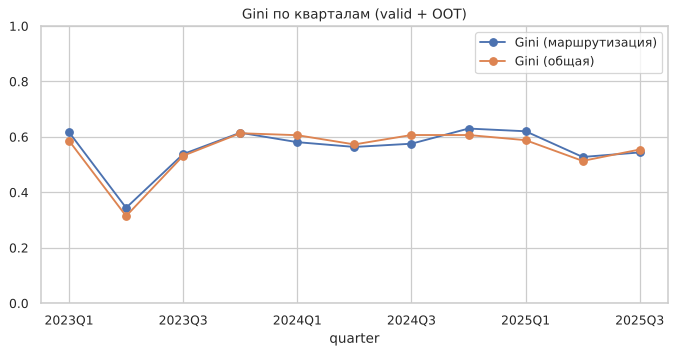

In [20]:
def apply_routing(df):
    """Скор каждой компании той моделью, которую выберет конвейер."""
    active = {
        seg for seg, r in compare.iterrows() if r["решение"].startswith("сегментная")
    }
    cards = {seg: devs[seg]["card"] for seg in active}
    out = []
    for _, r in df.iterrows():
        card = cards.get(r.segment, dev_general["card"])
        out.append(SC.score(card, to_facts(r)).score)
    return np.array(out)


pop["routed_score"] = apply_routing(pop)
pop["general_score"] = [
    SC.score(dev_general["card"], to_facts(r)).score for _, r in pop.iterrows()
]
q = (
    pop[pop["sample"] != "train"]
    .groupby("quarter")
    .apply(
        lambda d: pd.Series(
            {
                "n": len(d),
                "дефолт": d.target.mean(),
                "Gini (маршрутизация)": sl.gini(d.target, -d.routed_score),
                "Gini (общая)": sl.gini(d.target, -d.general_score),
            }
        )
    )
)
display(q.round(4))
q[["Gini (маршрутизация)", "Gini (общая)"]].plot(
    marker="o", figsize=(9, 4), title="Gini по кварталам (valid + OOT)"
)
plt.ylim(0, 1)
plt.show()
for part in ("valid", "oot"):
    d = pop[pop["sample"] == part]
    print(
        f"{part}: Gini итоговой схемы {sl.gini(d.target, -d.routed_score):.4f} vs общая {sl.gini(d.target, -d.general_score):.4f}"
    )

## 8. Калибровка PD и мастер-шкала A–E

Балл ранжирует, но для решения и лимита нужна вероятность дефолта. Калибруем `logit(PD) = a + b·Score` на train+valid модели (Platt scaling: балл линейен по лог-шансам, поэтому достаточно двух параметров). Затем мастер-шкала: грейд — диапазон PD, перевод в диапазон баллов через обратную калибровку.

| Грейд | PD | Решение |
|---|---|---|
| A | < 2% | одобрение |
| B | 2–4% | одобрение / контрпредложение |
| C | 4–8% | ручной разбор, документы |
| D | 8–15% | контрпредложение с залогом / отказ |
| E | ≥ 15% | отказ |

`cutoff_score` модели — нижняя граница грейда D: ниже — автоматический отказ.

In [21]:
GRADES = [
    ("A", 0.0, 0.02),
    ("B", 0.02, 0.04),
    ("C", 0.04, 0.08),
    ("D", 0.08, 0.15),
    ("E", 0.15, 1.0),
]


def calibrate(dev):
    df = pd.concat([dev["data"]["train"][0], dev["data"]["valid"][0]])
    s = np.concatenate([dev["data"]["train"][1], dev["data"]["valid"][1]])
    m, _ = sl.logit_fit(pd.DataFrame({"score": s}), df.target)
    a, b = float(m.intercept_[0]), float(m.coef_[0][0])
    score_at = lambda pd_: (np.log(pd_ / (1 - pd_)) - a) / b
    grades = []
    for g, lo, hi in GRADES:  # PD растёт → балл падает
        s_hi = 9999.0 if lo == 0 else score_at(lo)
        s_lo = -9999.0 if hi == 1 else score_at(hi)
        grades.append(
            {
                "grade": g,
                "score_from": round(s_lo, 2),
                "score_to": round(s_hi, 2),
                "pd": None,
            }
        )
    dev["pd_a"], dev["pd_b"] = a, b
    card = dev["card"]
    dev["card"] = SC.Scorecard(
        card.model_id,
        card.base_score,
        card.bins,
        [SC.Grade(g["grade"], g["score_from"], g["score_to"], 0.0) for g in grades],
        a,
        b,
    )
    # PD грейда = средний откалиброванный PD внутри грейда на dev-выборке
    pd_dev = 1 / (1 + np.exp(-(a + b * s)))
    for g in grades:
        m_ = (s >= g["score_from"]) & (s < g["score_to"])
        g["pd"] = round(
            float(pd_dev[m_].mean())
            if m_.any()
            else (GRADES[[x[0] for x in GRADES].index(g["grade"])][1] + 1e-4),
            6,
        )
    dev["grades"] = grades
    dev["card"] = SC.Scorecard(
        card.model_id,
        card.base_score,
        card.bins,
        [SC.Grade(g["grade"], g["score_from"], g["score_to"], g["pd"]) for g in grades],
        a,
        b,
    )
    dev["cutoff"] = next(g["score_to"] for g in grades if g["grade"] == "E")
    return dev


for dev in [dev_general, *devs.values()]:
    calibrate(dev)


def grade_report(dev, part="oot"):
    df, s = dev["data"][part]
    g = [SC.grade_for(dev["card"], v) for v in s]
    pdv = [SC.pd_from_score(dev["card"], v) for v in s]
    t = (
        pd.DataFrame({"grade": g, "target": df.target.values, "pd": pdv})
        .groupby("grade")
        .agg(
            n=("target", "size"),
            дефолт_факт=("target", "mean"),
            pd_прогноз=("pd", "mean"),
        )
    )
    t["доля"] = t.n / t.n.sum()
    return t


for dev in [dev_general, *devs.values()]:
    print(
        f"\n{dev['name']}: a={dev['pd_a']:.3f}, b={dev['pd_b']:.5f}, cutoff (граница E) = {dev['cutoff']:.1f}"
    )
    display(pd.DataFrame(dev["grades"]))
    display(grade_report(dev).round(4))


msb_general: a=16.744, b=-0.03441, cutoff (граница E) = 537.0

msb_new_business: a=17.859, b=-0.03640, cutoff (граница E) = 538.2

msb_ip_micro: a=16.629, b=-0.03417, cutoff (граница E) = 537.3

msb_sme: a=16.205, b=-0.03353, cutoff (граница E) = 535.0


,grade,score_from,score_to,pd
0,A,599.7,9999,0.0111
1,B,579,599.7,0.0289
2,C,557.6,579,0.0561
3,D,537,557.6,0.1075
4,E,-9999,537,0.2393


,n,дефолт_факт,pd_прогноз,доля
grade,,,,
A,2761,0.0123,0.011,0.3849
B,1776,0.0293,0.0287,0.2476
C,1466,0.0471,0.0558,0.2043
D,765,0.102,0.1079,0.1066
E,406,0.2241,0.2387,0.0566


,grade,score_from,score_to,pd
0,A,597.5,9999,0.01536
1,B,577.9,597.5,0.02839
2,C,557.7,577.9,0.05536
3,D,538.2,557.7,0.1057
4,E,-9999,538.2,0.242


,n,дефолт_факт,pd_прогноз,доля
grade,,,,
A,169,0,0.015,0.1806
B,229,0.0262,0.0287,0.2447
C,219,0.0594,0.0548,0.234
D,171,0.1111,0.1037,0.1827
E,148,0.1824,0.2376,0.1581


,grade,score_from,score_to,pd
0,A,600.5,9999,0.01094
1,B,579.6,600.5,0.02863
2,C,558,579.6,0.05631
3,D,537.3,558,0.1079
4,E,-9999,537.3,0.2463


,n,дефолт_факт,pd_прогноз,доля
grade,,,,
A,1933,0.0119,0.0109,0.4191
B,1148,0.027,0.0287,0.2489
C,865,0.0439,0.056,0.1876
D,444,0.1059,0.1074,0.0963
E,222,0.2162,0.2451,0.0481


,grade,score_from,score_to,pd
0,A,599.3,9999,0.009648
1,B,578,599.3,0.02867
2,C,556.1,578,0.0564
3,D,535,556.1,0.1074
4,E,-9999,535,0.2325


,n,дефолт_факт,pd_прогноз,доля
grade,,,,
A,805,0.0174,0.0097,0.4951
B,330,0.0394,0.0288,0.203
C,273,0.0549,0.0564,0.1679
D,146,0.1096,0.1079,0.0898
E,72,0.1944,0.2326,0.0443


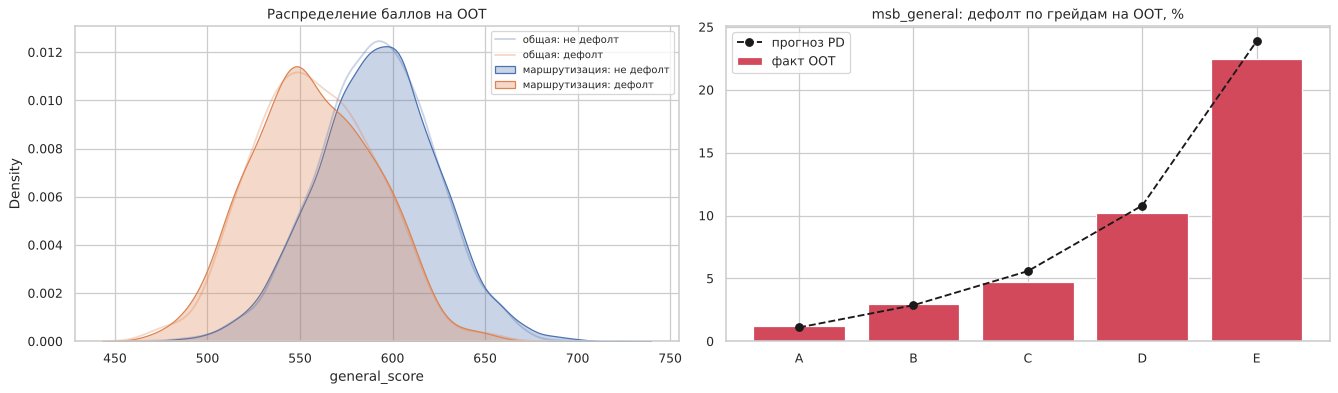

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
d = pop[pop["sample"] == "oot"]
for lbl, col in [("общая", "general_score"), ("маршрутизация", "routed_score")]:
    sns.kdeplot(
        d.loc[d.target == 0, col],
        ax=axes[0],
        label=f"{lbl}: не дефолт",
        fill=lbl == "маршрутизация",
        alpha=0.3,
    )
    sns.kdeplot(
        d.loc[d.target == 1, col],
        ax=axes[0],
        label=f"{lbl}: дефолт",
        fill=lbl == "маршрутизация",
        alpha=0.3,
    )
axes[0].set_title("Распределение баллов на OOT")
axes[0].legend(fontsize=8)
t = grade_report(dev_general)
axes[1].bar(t.index, t["дефолт_факт"] * 100, color="#d1495b", label="факт OOT")
axes[1].plot(t.index, t["pd_прогноз"] * 100, "ko--", label="прогноз PD")
axes[1].set_title("msb_general: дефолт по грейдам на OOT, %")
axes[1].legend()
plt.tight_layout()
plt.show()

**Валидация, итог.** Проверяем по каждой модели: (1) Gini на OOT не ниже valid более чем на 0,10 — нет переобучения; (2) PSI баллов train→OOT < 0,1 — популяция стабильна; (3) фактический дефолт монотонно растёт от A к E — шкала ранжирует; (4) средний прогноз PD близок к факту — калибровка адекватна; (5) все β < 0 и p < 0,05, VIF < 5 — веса интерпретируемы.

## 9. Экспорт моделей и выборки

`ml/artifacts/models.json` — сегменты с правилами и все версии моделей (бины, баллы, шкала, метрики). Загрузчик `python -m app.ml.load_synthetic` кладёт его в БД:
* `scoring_segments` — правило «когда применять» + приоритет; выключенные сегменты сохраняются с `is_active = false`;
* `model_versions` — модель, версия, `segment_code`, статус (`champion` — рабочая для сегмента, `challenger` — наблюдаем), метрики, `cutoff_score`, `params` (шкала и калибровка PD);
* `model_features`, `scorecard_bins`, `rating_scale`, `feature_definitions`.

Контрольные примеры (`examples`) — векторы признаков с ожидаемым баллом: юнит-тест приложения проверяет, что конвейер считает те же баллы, что и ноутбук.

In [23]:
VERSION = "1.0.0"
TRAIN_FROM, TRAIN_TO = (
    pop.as_of_date.min().date(),
    (OOT_FROM - pd.Timedelta(days=1)).date(),
)
OOT_TO = pop.as_of_date.max().date()


def export_model(dev, segment, status, model_type="scorecard"):
    m = metrics(dev)
    return {
        "model_name": dev["name"],
        "version": VERSION,
        "model_type": model_type,
        "segment_code": segment,
        "status": status,
        "target_definition": "Дефолт (90+ дней просрочки или банкротство) в течение 12 мес. после даты заявки",
        "train_from": TRAIN_FROM.isoformat(),
        "train_to": TRAIN_TO.isoformat(),
        "oot_from": OOT_FROM.date().isoformat(),
        "oot_to": OOT_TO.isoformat(),
        "gini_train": round(float(m.loc["train", "Gini"]), 4),
        "gini_oot": round(float(m.loc["oot", "Gini"]), 4),
        "ks_oot": round(float(m.loc["oot", "KS"]), 4),
        "cutoff_score": round(float(dev["cutoff"]), 2),
        "artifact_uri": "ml/artifacts/models.json",
        "params": {
            "pdo": SC.PDO,
            "base_score": SC.BASE_SCORE,
            "base_odds": SC.BASE_ODDS,
            "intercept_points": dev["card"].base_score,
            "pd_a": round(dev["pd_a"], 6),
            "pd_b": round(dev["pd_b"], 8),
            "gini_valid": round(float(m.loc["valid", "Gini"]), 4),
            "psi_oot": round(float(m.loc["oot", "PSI vs train"]), 4),
            "n_train": int(m.loc["train", "n"]),
            "n_oot": int(m.loc["oot", "n"]),
            "dataset_code": manifest["dataset_code"],
        },
        "features": [
            {
                "code": f,
                "coefficient": round(dev["betas"][f], 6),
                "information_value": round(float(dev["ivs"][f]), 5),
            }
            for f in dev["chosen"]
        ],
        "bins": dev["bins"],
        "grades": dev["grades"],
    }


active_segments = {
    seg for seg, r in compare.iterrows() if r["решение"].startswith("сегментная")
}
models_out = [export_model(dev_general, "all", "champion")]
for seg, dev in devs.items():
    models_out.append(
        export_model(dev, seg, "champion" if seg in active_segments else "challenger")
    )
segments_out = [
    {**r, "is_active": r["code"] == "all" or r["code"] in active_segments}
    for r in SEGMENT_RULES
]

examples = []
for _, r in pop[pop["sample"] == "oot"].sample(12, random_state=1).iterrows():
    seg = r.segment if r.segment in active_segments else "all"
    dev = devs.get(seg, dev_general)
    out = SC.score(dev["card"], to_facts(r))
    examples.append(
        {
            "segment": SC.match_segment(segments, to_facts(r)),
            "model": dev["name"],
            "features": to_facts(r),
            "score": out.score,
            "grade": out.grade,
            "pd": out.pd,
        }
    )

export = {
    "dataset_code": manifest["dataset_code"],
    "version": VERSION,
    "created": pd.Timestamp.now(tz="Europe/Moscow").date().isoformat(),
    "segments": segments_out,
    "models": models_out,
    "gbm_challenger": {
        "model_name": "msb_gbm",
        "gini": gbm_metrics["Gini"].round(4).to_dict(),
    },
    "features": [
        {"code": c, "name": v[0], "data_type": v[1], "source": v[2], "formula": v[3]}
        for c, v in F.FEATURE_CATALOG.items()
    ],
    "examples": examples,
}


def _json_default(o):
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, (np.bool_,)):
        return bool(o)
    raise TypeError(type(o))


(ARTIFACTS / "models.json").write_text(
    json.dumps(export, ensure_ascii=False, indent=1, default=_json_default),
    encoding="utf-8",
)

samples = feats[["company_key"]].merge(
    pop[["company_key", "sample", "segment"]], on="company_key", how="left"
)
samples["sample"] = samples["sample"].fillna("excluded")
samples.to_csv(
    DATA / "samples.csv.gz", index=False, compression={"method": "gzip", "mtime": 0}
)
print(
    "models.json:",
    [
        (m["model_name"], m["segment_code"], m["status"], m["gini_oot"])
        for m in models_out
    ],
)
print("сегменты:", [(s["code"], s["is_active"]) for s in segments_out])
display(samples["sample"].value_counts())

models.json: [('msb_general', 'all', 'champion', 0.534), ('msb_new_business', 'new_business', 'champion', 0.5417), ('msb_ip_micro', 'ip_micro', 'challenger', 0.5415), ('msb_sme', 'sme', 'champion', 0.4949)]
сегменты: [('new_business', True), ('ip_micro', False), ('sme', True), ('all', True)]


,count
sample,
train,24471
valid,8157
oot,7174
excluded,198


## 10. Итог (model card)

**Когда какая модель применяется** (порядок проверки — `priority` в `scoring_segments`, первый подошедший активный сегмент; у сегмента рабочая модель — `champion`):

| priority | сегмент | условие | модель |
|---|---|---|---|
| 10 | `new_business` | возраст бизнеса < 12 мес. **или** нет ни одного кредита в БКИ | `msb_new_business` |
| 20 | `ip_micro` (выключен) | ИП **или** микропредприятие | → `all` |
| 30 | `sme` | ЮЛ категории small / medium | `msb_sme` |
| 100 | `all` | все остальные | `msb_general` |

Перед скорингом всегда — стоп-факторы (банкротство, красная зона ЗСК → отказ без модели). После — грейд A–E по мастер-шкале модели и матрица решений.

In [24]:
card_rows = []
for m in models_out:
    card_rows.append(
        {
            "модель": m["model_name"],
            "сегмент": m["segment_code"],
            "статус": m["status"],
            "признаков": len(m["features"]),
            "Gini train": m["gini_train"],
            "Gini valid": m["params"]["gini_valid"],
            "Gini OOT": m["gini_oot"],
            "KS OOT": m["ks_oot"],
            "PSI OOT": m["params"]["psi_oot"],
            "cutoff": m["cutoff_score"],
        }
    )
card_rows.append(
    {
        "модель": "msb_gbm",
        "сегмент": "all",
        "статус": "ориентир (не в БД)",
        "признаков": len(gbm_cols),
        "Gini train": gbm_metrics.loc["train", "Gini"],
        "Gini valid": gbm_metrics.loc["valid", "Gini"],
        "Gini OOT": gbm_metrics.loc["oot", "Gini"],
        "KS OOT": gbm_metrics.loc["oot", "KS"],
    }
)
display(pd.DataFrame(card_rows).set_index("модель").round(4))

,сегмент,статус,признаков,Gini train,Gini valid,Gini OOT,KS OOT,PSI OOT,cutoff
модель,,,,,,,,,
msb_general,all,champion,16,0.575,0.5611,0.534,0.404,0.0013,537
msb_new_business,new_business,champion,5,0.5062,0.5729,0.5417,0.4099,0.0091,538.2
msb_ip_micro,ip_micro,challenger,13,0.5908,0.56,0.5415,0.4269,0.0018,537.3
msb_sme,sme,champion,10,0.6175,0.5386,0.4949,0.3909,0.0108,535
msb_gbm,all,ориентир (не в БД),28,0.7141,0.5433,0.559,0.4363,NaN,NaN
